# Análisis Exploratorio de Datos GasHisSDB

Clasificación binaria (Normal vs Abnormal) de imágenes histopatologicasa de tejido gástrico

Análisis exploratorio del dataset **GasHisSDB**
(Gastric Histopathology Sub-size Image Database). El dataset contiene parches recortados de imágenes
completas (WSI, *Whole Slide Images*) teñidas, en tres resoluciones (80×80, 120×120 y 160×160 px) y dos clases (`Normal`, `Abnormal`).

El objetivo del EDA no es solo describir el dataset, sino **detectar riesgos
metodológicos** que condicionan la validez de los resultados posteriores:

- Balance de clases y su impacto en la estrategia de entrenamiento y métricas.
- **Fuga de datos (*data leakage*) a nivel de WSI** — el riesgo más crítico en
  histopatología de parches.
- Duplicados / *near-duplicates* que inflarían artificialmente el rendimiento.
- Diferencias sistemáticas de color/tinción entre clases que el modelo podría explotar
  como **atajo espurio** (*shortcut learning*) en lugar de aprender morfología real.
- Estadísticas de normalización específicas del dominio (frente a las de ImageNet).





Importamos las librerías, fijamos la semilla para que sea reproducible.

In [1]:
import os
import re
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import yaml

try:
    import imagehash
    HAS_IMAGEHASH = True
except ImportError:
    HAS_IMAGEHASH = False

%matplotlib inline
warnings.filterwarnings("ignore")


SEED = 42
random.seed(SEED)
np.random.seed(SEED)


sns.set_theme(style="whitegrid", context="notebook") #nuevo descubrimiento, marca estilo para todo el notebook
plt.rcParams["figure.dpi"] = 110

# rutas teniendo en cuenta el docker
PROJECT_ROOT = Path.cwd()
DATASET_ROOT = Path("dataset/GasHisSDB/GasHisSDB")
RESULTS_DIR  = Path("results")
EDA_DIR      = RESULTS_DIR / "eda"
CONFIGS_DIR  = Path("configs")
for d in (EDA_DIR, CONFIGS_DIR):
    d.mkdir(parents=True, exist_ok=True)

RESOLUTIONS    = ["80", "120", "160"]
CLASSES        = ["Normal", "Abnormal"]
CLASS_COLORS   = {"Normal": "#4C72B0", "Abnormal": "#C44E52"}
EXPECTED_TOTAL = 245196 #imágenes totales que dice el readme que deberían haber

assert DATASET_ROOT.exists(), f"No existe {DATASET_ROOT.resolve()} — revisa el bind mount de Docker."

print("Raiz:", PROJECT_ROOT)
print("Dataset:", DATASET_ROOT.resolve())
print("Versión de numpy y pandas:", np.__version__, "/", pd.__version__)
print("imagehash:", HAS_IMAGEHASH)


def list_images(res, cls):
    '''Devuelve la lista ordenada de PNG de una carpeta resolución/clase.'''

    class_dir =  DATASET_ROOT / res / cls
    image_paths = class_dir.glob("*.png")
    sorted_image_paths = sorted(image_paths)

    return sorted_image_paths


def save_fig(fig, name):
    '''Guarda una figura en results/eda/ además de mostrarla inline.'''
    path = EDA_DIR / name

    fig.savefig(path, dpi=150, bbox_inches="tight")

    print(f"[figura guardada en] {path}")


Raiz: /workspace
Dataset: /workspace/dataset/GasHisSDB/GasHisSDB
Versión de numpy y pandas: 1.26.4 / 2.2.2
imagehash: True


## Balance de clases
Recorremos los ficheros y calculamos un inventario de cuantas imágenes tenemos. A continuación resumimos el número de imágenes
por resolución y clase, y comprobamos que el total coincide con el esperado
(**245 196** imágenes según el README oficial del dataset).

In [2]:
inventory_csv_path = RESULTS_DIR / "dataset_inventory.csv"

if inventory_csv_path.exists():
    inv_df = pd.read_csv(inventory_csv_path)

else:
    print("No existe results/dataset_inventory.csv")

    inv_rows = []

    for res in RESOLUTIONS:
        for cls in CLASSES:
            image_paths = list_images(res,cls)
            number_of_images = len(image_paths)

            row = {"resolution": int(res), "class": cls, "n_images": number_of_images}

            inv_rows.append(row)

    inv = pd.DataFrame(inv_rows)
    inv.to_csv(inventory_csv_path, index=False)
    print("Inventario guardado en", inventory_csv_path)

inv_df


,resolution,class,n_images
0,80,Normal,87500
1,80,Abnormal,59151
2,120,Normal,40460
3,120,Abnormal,24801
4,160,Normal,20160
5,160,Abnormal,13124


In [3]:
# Tabla resumen
df = inv_df.pivot(index="resolution", columns="class", values="n_images")[["Normal", "Abnormal"]]

df["Total"] = df["Normal"] + df["Abnormal"]
df["%Abnormal"] = (df["Abnormal"] / df["Total"] * 100).round(1)

total_row = pd.DataFrame({
    "Normal":    [df["Normal"].sum()],
    "Abnormal":  [df["Abnormal"].sum()],
    "Total":     [df["Total"].sum()],
    "% de Abnormal": [round(df["Abnormal"].sum() / df["Total"].sum() * 100, 1)],
}, index=["Total"])
inv_table = pd.concat([df, total_row])

total_images = int(inv_df["n_images"].sum())
print(f"Total de imágenes: {total_images} (esperado {EXPECTED_TOTAL})")
if total_images != EXPECTED_TOTAL:
    print("[AVISO] El total NO coincide con el esperado del README.")
else:
    print("[OK] El total coincide con el README.")
inv_table


Total de imágenes: 245196 (esperado 245196)
[OK] El total coincide con el README.


,Normal,Abnormal,Total,%Abnormal,% de Abnormal
80,87500,59151,146651,40.3,NaN
120,40460,24801,65261,38.0,NaN
160,20160,13124,33284,39.4,NaN
Total,148120,97076,245196,NaN,39.6


[figura guardada en] results/eda/02_balance_clases.png


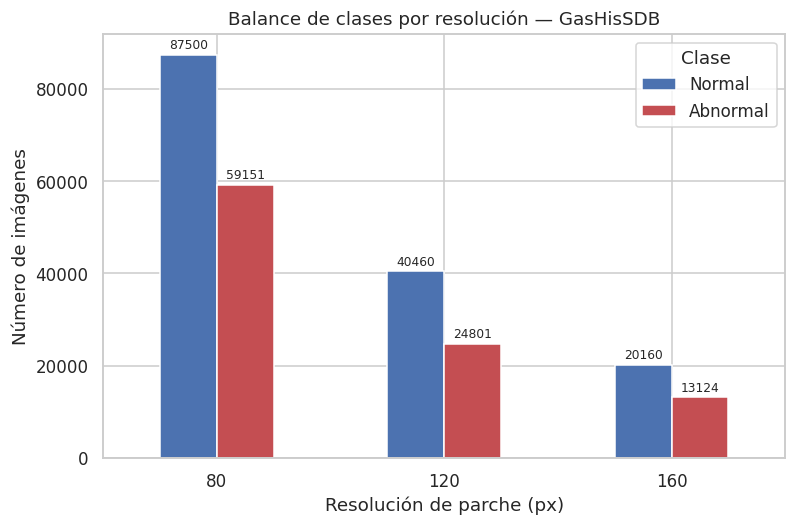

In [4]:
# Gráfico de barras del balance de clases por resolución
plot_df = inv_df.pivot(index="resolution", columns="class", values="n_images")[["Normal", "Abnormal"]]

fig, ax = plt.subplots(figsize=(8, 5))
plot_df.plot(kind="bar", ax=ax, color=[CLASS_COLORS["Normal"], CLASS_COLORS["Abnormal"]])
ax.set_title("Balance de clases por resolución — GasHisSDB")
ax.set_xlabel("Resolución de parche (px)")
ax.set_ylabel("Número de imágenes")
ax.legend(title="Clase")
for c in ax.containers:
    ax.bar_label(c, fmt="%d", fontsize=8, padding=2)
plt.xticks(rotation=0)
save_fig(fig, "02_balance_clases.png")
plt.show()


el dataset presenta un desbalance moderado y consistente en todas las resoluciones: la clase
`Normal` es mayoritaria frente a `Abnormal` en las tres resoluciones con una relación aproximada de 60-40 %.
No es un desbalance extremo, pero es suficiente para que la *accuracy* simple sea
engañosa (un clasificador trivial que prediga siempre `Normal` alcanzaría ~60 %). Esto
motiva el uso de métricas sensibles al desbalance (sensibilidad/recall de `Abnormal`,
F1, AUC-PR, matriz de confusión) y opcionalmente, class weights o data augmentation de
la clase minoritaria.

## Exploración visual

Mostramos una cuadrícula 4×4 de imágenes aleatorias para cada una de las
6 combinaciones resolución y clase. El objetivo es familiarizarse con la apariencia del
tejido, la variabilidad del tinte en las imágenes y posibles errores (parches desenfocados,
fondo sin tejido, etc.).

In [5]:
#función reutilizable de muestra de imagenes
def show_grid(res, cls, n=16, ncols=4):
    files  = list_images(res, cls)
    sample = random.Random(SEED).sample(files, min(n, len(files)))
    nrows  = (len(sample) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.2, nrows * 2.2))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")
    for ax, f in zip(axes, sample):
        ax.imshow(Image.open(f).convert("RGB"))
        ax.set_title(f.name, fontsize=6)
    fig.suptitle(f"Ejemplos aleatorios resolución: {res}px - clase: {cls}", y=1.0, fontsize=11)
    fig.tight_layout()
    save_fig(fig, f"03_muestras_{res}_{cls}.png")

    plt.show()


[figura guardada en] results/eda/03_muestras_80_Normal.png


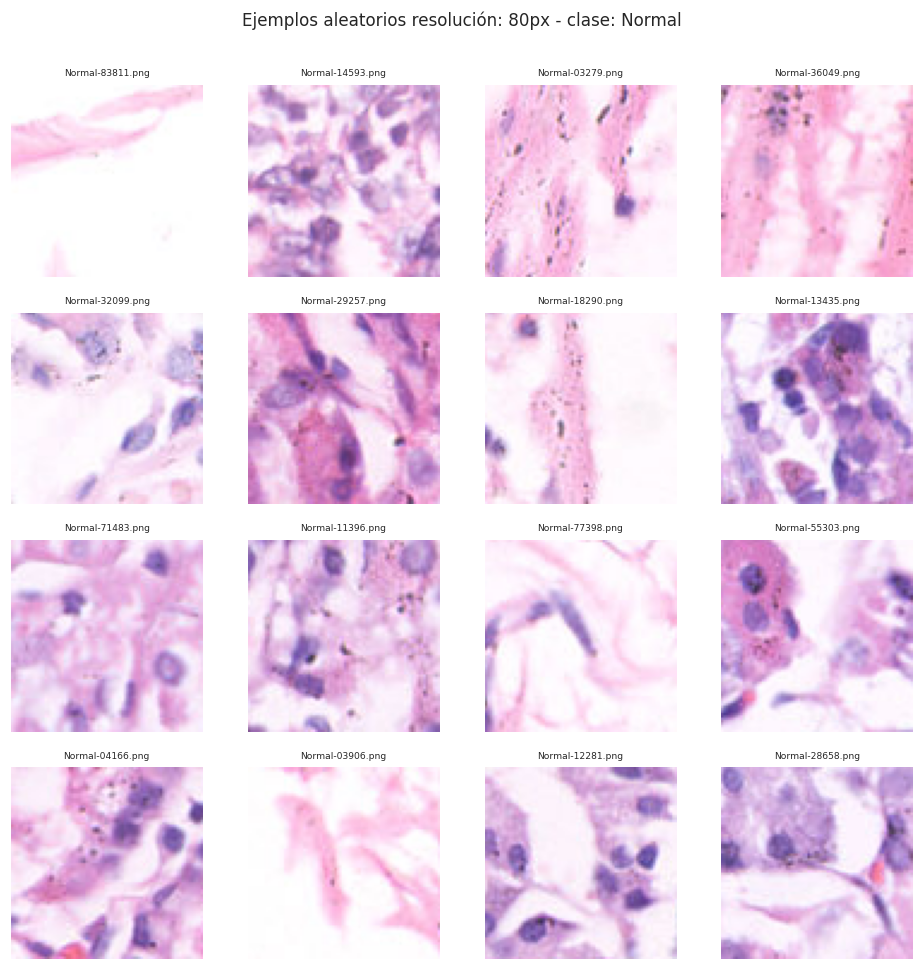

In [6]:
show_grid("80", "Normal")

[figura guardada en] results/eda/03_muestras_80_Abnormal.png


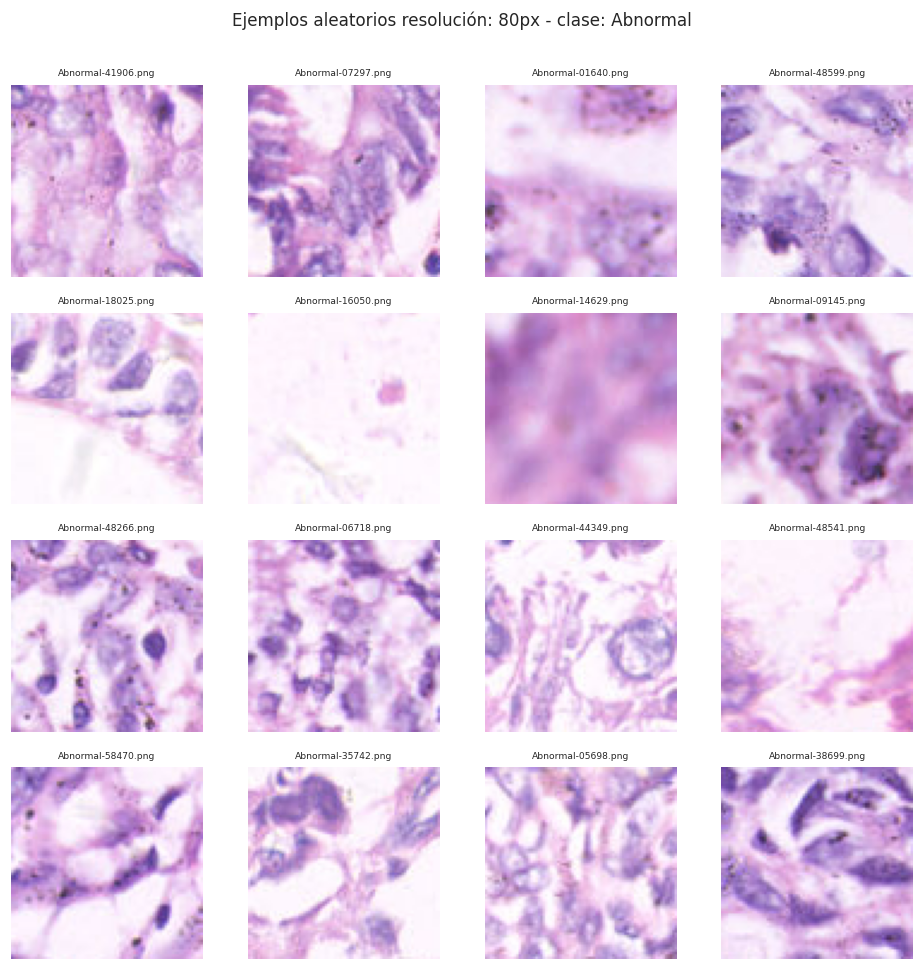

In [7]:
show_grid("80", "Abnormal")

[figura guardada en] results/eda/03_muestras_120_Normal.png


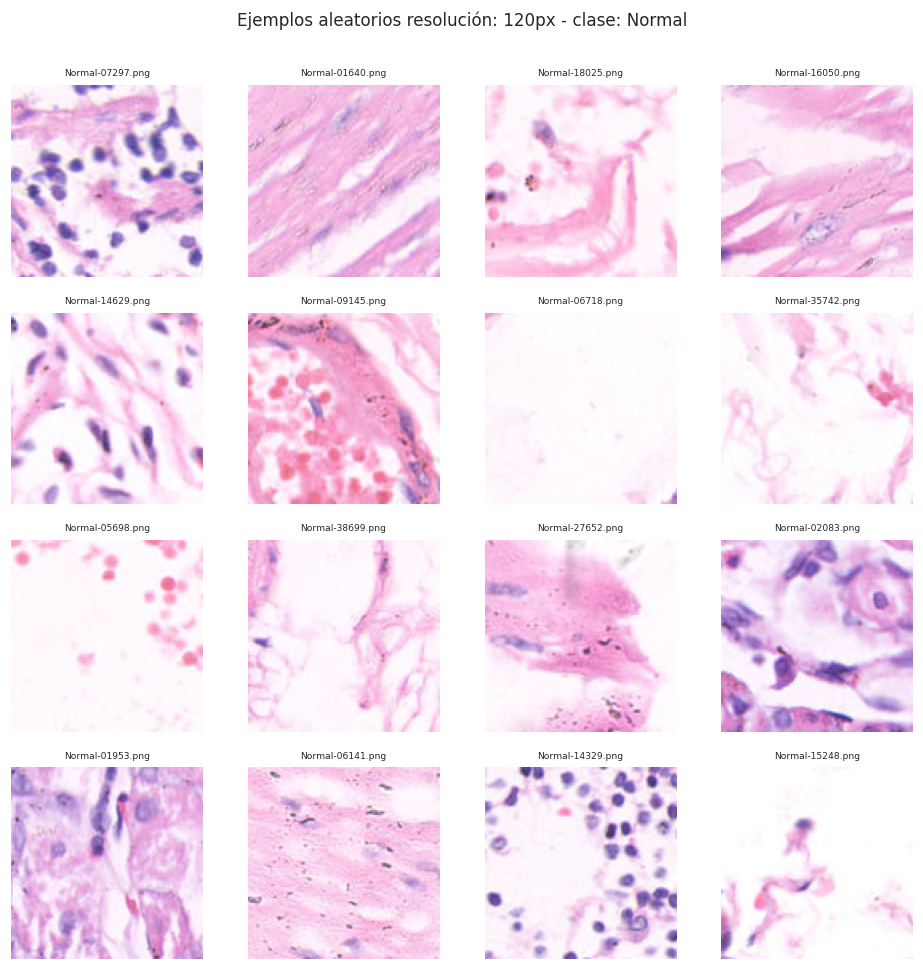

In [8]:
show_grid("120", "Normal")

[figura guardada en] results/eda/03_muestras_120_Abnormal.png


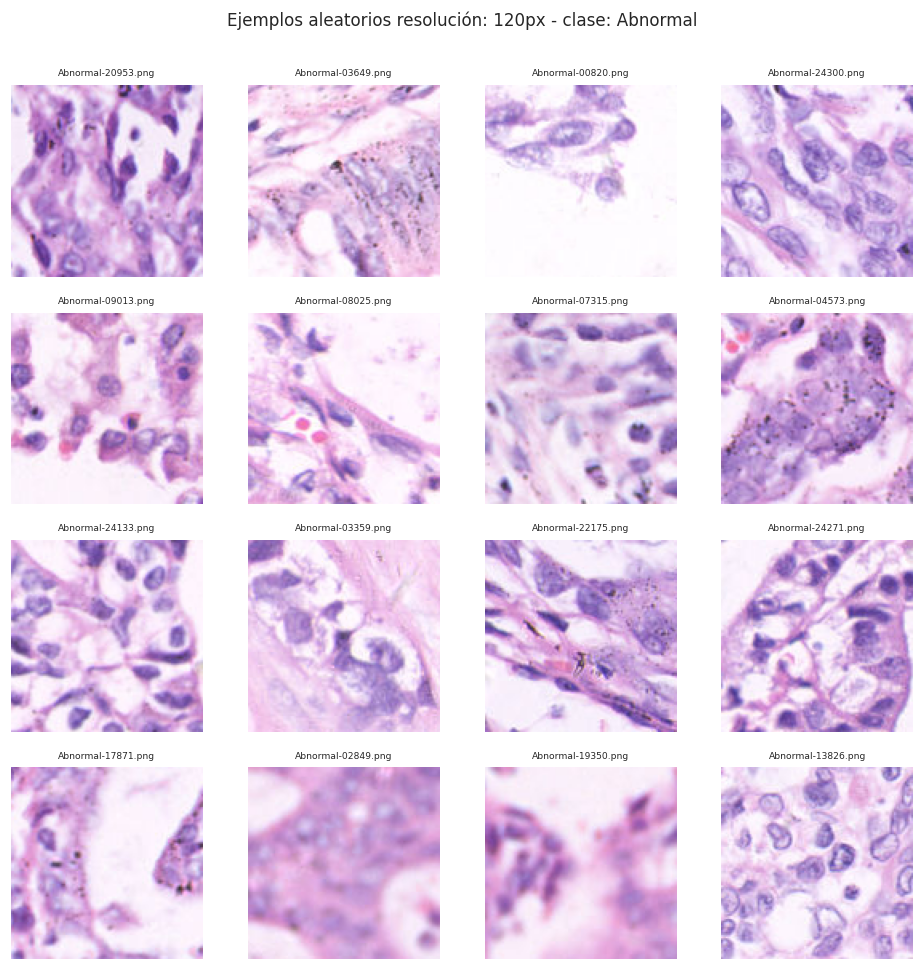

In [9]:
show_grid("120", "Abnormal")

[figura guardada en] results/eda/03_muestras_160_Normal.png


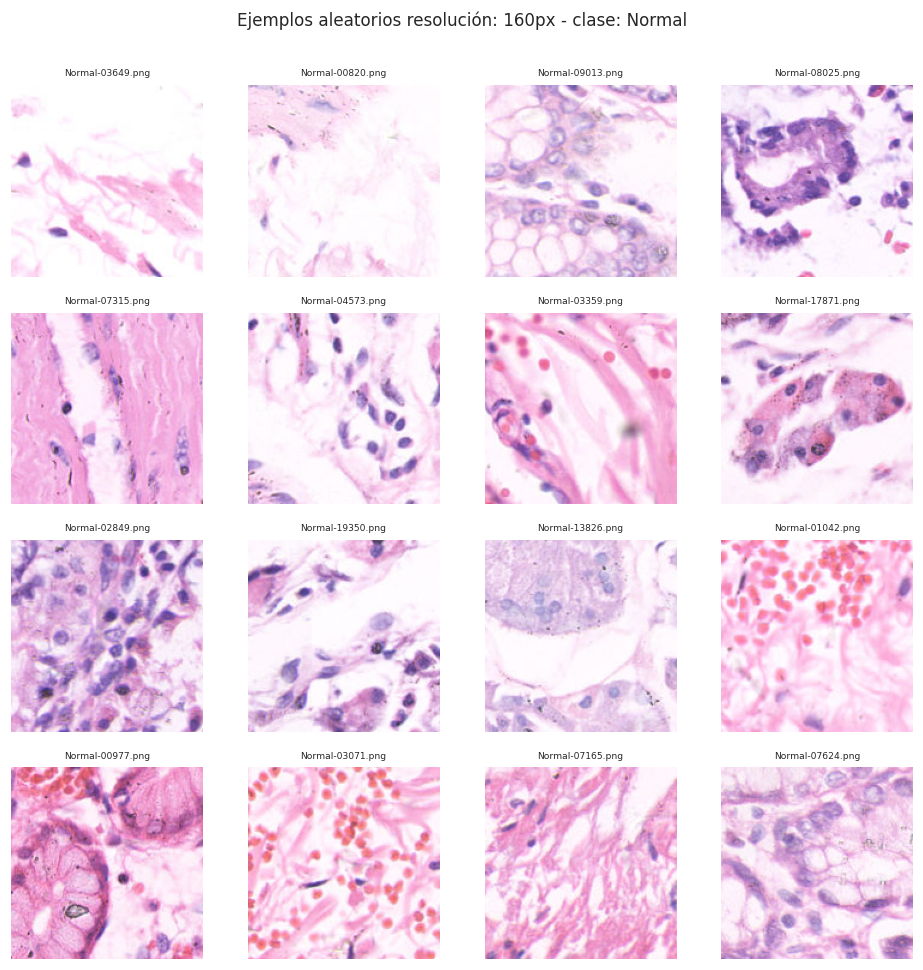

In [10]:
show_grid("160", "Normal")

[figura guardada en] results/eda/03_muestras_160_Abnormal.png


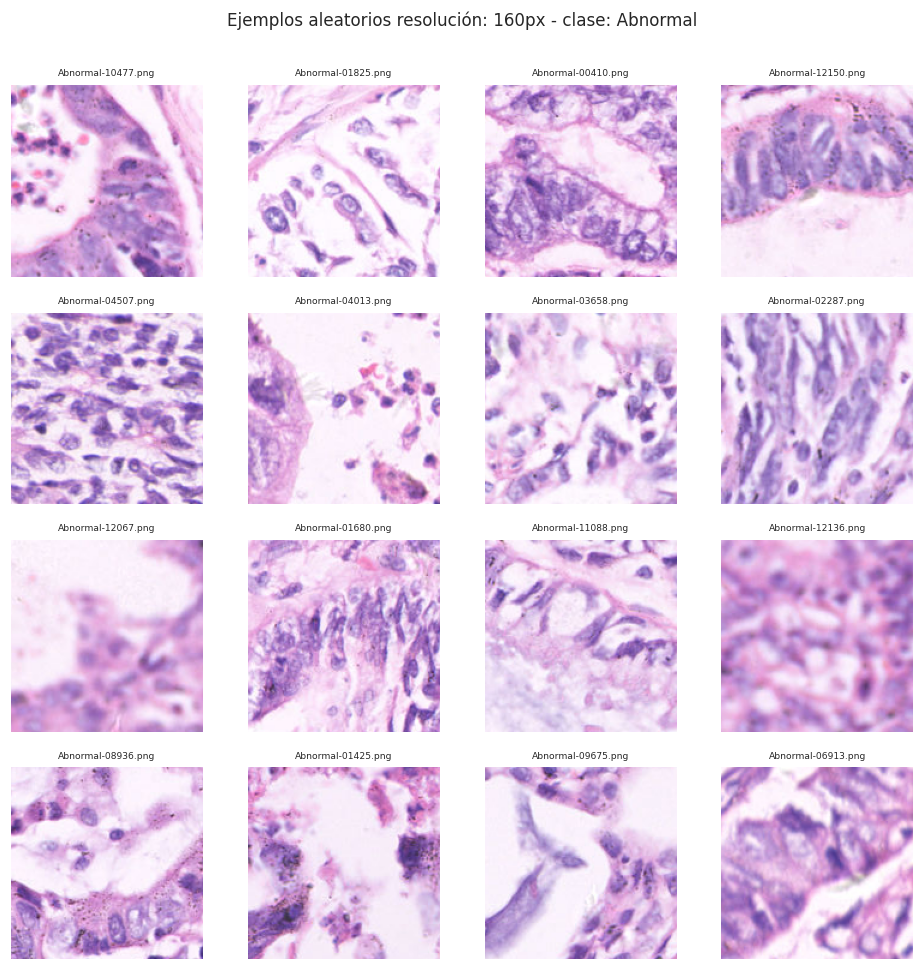

In [11]:
show_grid("160", "Abnormal")

## Estadísticas de intensidad y color

A simple vista la pricipal diferencia entre las dos clases de imágenes (`Normal` y `Abnormal`), parece que podría estar diferencia por diferentes tonalidades de color presentes en un conjunto de los datos. Por este motivo parece interesante estudiar y explorar diversas estadísticas del color.

Sobre una muestra de **5 000 imágenes por resolución** (estratificada por clase según su
proporción real) calculamos la **media y desviación típica por canal RGB** (en `[0, 1]`).

Dos objetivos:

1. **Detección de atajos**: si las clases `Normal` y `Abnormal` difieren de forma
   sistemática en color/iluminación (p. ej. por lotes de tinción distintos), el modelo
   podría discriminar por el color global del parche — un sesgo peligroso que no generalizaría a otro laboratorio.
2. **Estadísticas de normalización específicas del dominio**: las guardamos en
   `configs/normalization_stats.yaml` para usarlas en `transforms.Normalize` durante el
   entrenamiento, en lugar de los valores por defecto de ImageNet (imágenes naturales,
   dominio muy distinto al de la tinción H&E).

In [ ]:
SAMPLE_STATS  = 5000

stats_records = []   # media por imagen y canal (rgb?) con clases
norm_stats    = {}   # media/std global por res

rng = random.Random(SEED)

for res in RESOLUTIONS:
    image_paths_by_class = {}
    image_counts_class = {}

    for cls in CLASSES:
        class_image_paths = list_images(res, cls)

        number_class_images = len(class_image_paths)

        image_paths_by_class[cls] = class_image_paths
        image_counts_class[cls] = number_class_images

    total_number_of_images = sum(image_counts_class.values())


    channel_sum = np.zeros(3, dtype=np.float64)
    channel_squared_sum = np.zeros(3, dtype=np.float64)

    # total de píxeles procesados
    total_number_of_pixels = 0

    for cls in CLASSES:
        class_image_paths = image_paths_by_class[cls]
        number_of_class_images = image_counts_class[cls]

        class_proportion = (number_of_class_images / total_number_of_images)


        desired_sample_size = (SAMPLE_STATS * class_proportion)

        rounded_sample_size = round(desired_sample_size)

        sample_size = int(rounded_sample_size)
        sample_size = min(sample_size, number_of_class_images)

        sampled_image_paths = rng.sample(class_image_paths, sample_size)


        for image_path in sampled_image_paths:
            with Image.open(image_path) as image:
                rgb_image = image.convert("RGB")

                image_array = np.asarray(rgb_image, dtype=np.float64)

            image_array = image_array / 255.0

            flattened_pixels = image_array.reshape(-1, 3)

            red_values = flattened_pixels[:, 0]
            green_values = flattened_pixels[:, 1]
            blue_values = flattened_pixels[:, 2]

            red_mean = red_values.mean()
            green_mean = green_values.mean()
            blue_mean = blue_values.mean()

            resolution_number = int(res)

            image_stats = {
                "resolution": resolution_number,
                "class": cls,
                "R": red_mean,
                "G": green_mean,
                "B": blue_mean
            }

            stats_records.append(image_stats)

            image_channel_sum = flattened_pixels.sum(axis=0)


            squared_pixels = flattened_pixels ** 2

            image_channel_squared_sum = squared_pixels.sum(axis=0)

            number_of_image_pixels = flattened_pixels.shape[0]

            channel_sum = (channel_sum + image_channel_sum)
            channel_squared_sum = (channel_squared_sum + image_channel_squared_sum)

            total_number_of_pixels = (total_number_of_pixels + number_of_image_pixels)


    global_channel_mean = (channel_sum / total_number_of_pixels)

    mean_of_squared_values = (channel_squared_sum / total_number_of_pixels)


    squared_channel_mean = (global_channel_mean ** 2)

    channel_variance = ( mean_of_squared_values - squared_channel_mean)
    channel_variance = np.maximum(channel_variance, 0)

    global_channel_std = np.sqrt(channel_variance)



    rounded_mean = []

    for value in global_channel_mean:
        numeric_value = float(value)
        rounded_value = round(numeric_value, 4)

        rounded_mean.append(rounded_value)


    rounded_std = []

    for value in global_channel_std:
        numeric_value = float(value)
        rounded_value = round(numeric_value, 4)

        rounded_std.append(rounded_value)

    resolution_stats = {"mean": rounded_mean,"std": rounded_std}

    norm_stats[res] = resolution_stats

    print(f"Resolución: {res}px")
    print("Media RGB:", rounded_mean)
    print("Desviación típica RGB:", rounded_std)


stats_df = pd.DataFrame(stats_records)

number_of_sampled_images = len(stats_df)

print("Imágenes procesadas en total:",number_of_sampled_images)

stats_df.head()


Resolución: 80px
Media RGB: [0.9019, 0.7846, 0.9066]
Desviación típica RGB: [0.1276, 0.1786, 0.0993]
Resolución: 120px
Media RGB: [0.9035, 0.7863, 0.907]
Desviación típica RGB: [0.1262, 0.1778, 0.0995]
Resolución: 160px
Media RGB: [0.9041, 0.7873, 0.9079]
Desviación típica RGB: [0.1259, 0.1774, 0.0983]
Imágenes procesadas en total: 15000


,resolution,class,R,G,B
0,80,Normal,0.997309,0.966314,0.986158
1,80,Normal,0.869465,0.730374,0.873356
2,80,Normal,0.961881,0.818846,0.918847
3,80,Normal,0.967116,0.776842,0.890595
4,80,Normal,0.935471,0.868281,0.945966


In [13]:
# Comparación intensidad media por clase y canal
comp = (stats_df.groupby(["resolution", "class"])[["R", "G", "B"]]
        .agg(["mean", "std"]).round(4))
comp


R               G               B        
                       mean     std    mean     std    mean     std
resolution class                                                   
80         Abnormal  0.8639  0.0553  0.7418  0.0802  0.8912  0.0393
           Normal    0.9276  0.0556  0.8136  0.0967  0.9171  0.0501
120        Abnormal  0.8658  0.0493  0.7434  0.0727  0.8920  0.0357
           Normal    0.9267  0.0520  0.8127  0.0913  0.9162  0.0483
160        Abnormal  0.8675  0.0466  0.7464  0.0687  0.8934  0.0336
           Normal    0.9280  0.0507  0.8139  0.0879  0.9173  0.0446

In [14]:
# Diferencia de intensidad media Abnormal - Normal (sesgo de color?)
delta_rows = []
for res in RESOLUTIONS:
    sub = stats_df[stats_df.resolution == int(res)]
    mn  = sub[sub["class"] == "Normal"][["R", "G", "B"]].mean()
    ma  = sub[sub["class"] == "Abnormal"][["R", "G", "B"]].mean()
    d   = ma - mn
    delta_rows.append({"resolution": int(res),
                       "dR (Abn-Nor)": round(d.R, 4),
                       "dG (Abn-Nor)": round(d.G, 4),
                       "dB (Abn-Nor)": round(d.B, 4)})
    
    
delta_df = pd.DataFrame(delta_rows)
delta_df


,resolution,dR (Abn-Nor),dG (Abn-Nor),dB (Abn-Nor)
0,80,-0.0637,-0.0718,-0.0259
1,120,-0.0609,-0.0693,-0.0241
2,160,-0.0605,-0.0675,-0.0239


[figura guardada en] results/eda/04_intensidad_por_clase.png


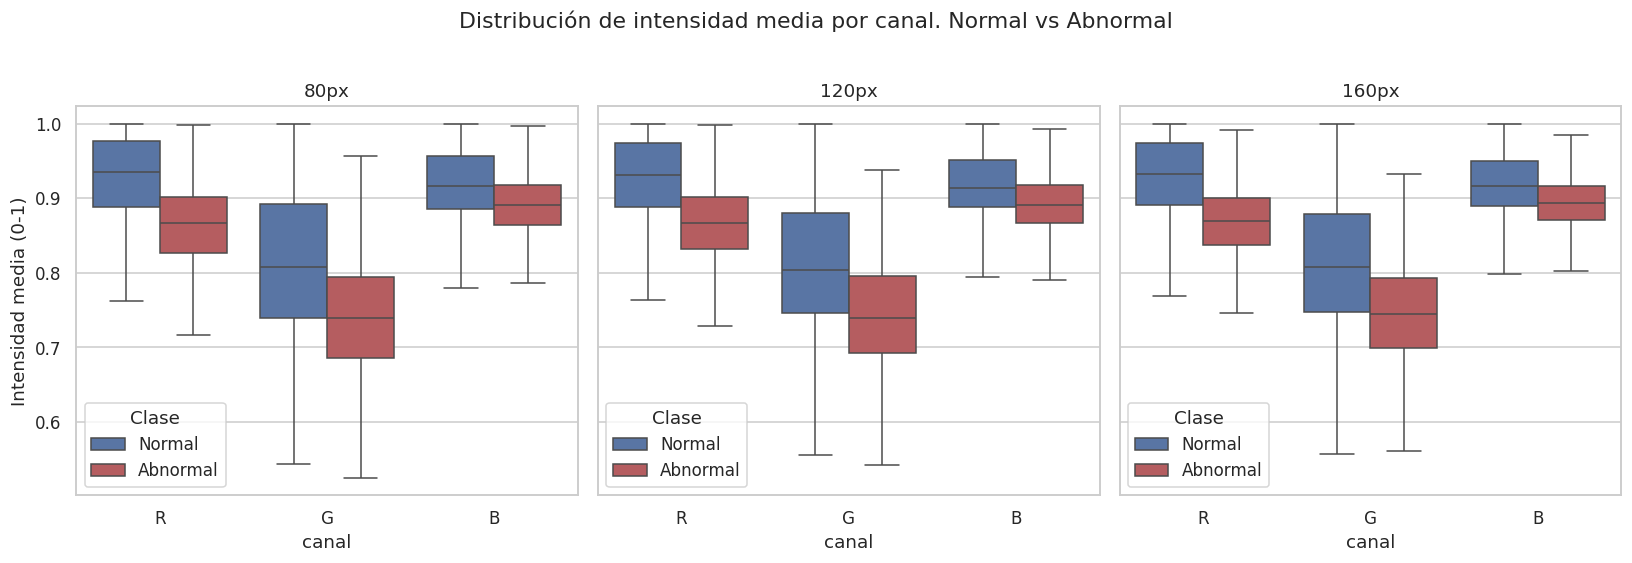

In [15]:
# Boxplots de intensidad mean
melted = stats_df.melt(id_vars=["resolution", "class"], value_vars=["R", "G", "B"],
                       var_name="canal", value_name="intensidad_media")

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, res in zip(axes, RESOLUTIONS):
    sub = melted[melted["resolution"] == int(res)]
    sns.boxplot(data=sub, x="canal", y="intensidad_media", hue="class",
                palette=CLASS_COLORS, ax=ax, showfliers=False)
    ax.set_title(f"{res}px")
    ax.set_ylabel("Intensidad media (0-1)")
    ax.legend(title="Clase", loc="lower left")


fig.suptitle("Distribución de intensidad media por canal. Normal vs Abnormal", y=1.02)
fig.tight_layout()
save_fig(fig, "04_intensidad_por_clase.png")
plt.show()


In [16]:
#guardamos resultados
norm_out = {}
for res in RESOLUTIONS:
    norm_out[f"gashisdb_{res}"] = {
        "resolution":      int(res),
        "mean":            norm_stats[res]["mean"],
        "std":             norm_stats[res]["std"],
        "n_sample_images": SAMPLE_STATS,
        "note": ("Media/std por canal RGB en [0,1], sobre muestra estratificada por clase "
                 "(seed 42). Usar en transforms.Normalize en lugar de los valores de ImageNet."),
    }

out_path = CONFIGS_DIR / "normalization_stats.yaml"
with open(out_path, "w", encoding="utf-8") as fh:
    yaml.safe_dump(norm_out, fh, sort_keys=False, allow_unicode=True)

print("Guardado:", out_path)
print("-" * 60)
print(out_path.read_text(encoding="utf-8"))


Guardado: configs/normalization_stats.yaml
------------------------------------------------------------
gashisdb_80:
  resolution: 80
  mean:
  - 0.9019
  - 0.7846
  - 0.9066
  std:
  - 0.1276
  - 0.1786
  - 0.0993
  n_sample_images: 5000
  note: Media/std por canal RGB en [0,1], sobre muestra estratificada por clase (seed
    42). Usar en transforms.Normalize en lugar de los valores de ImageNet.
gashisdb_120:
  resolution: 120
  mean:
  - 0.9035
  - 0.7863
  - 0.907
  std:
  - 0.1262
  - 0.1778
  - 0.0995
  n_sample_images: 5000
  note: Media/std por canal RGB en [0,1], sobre muestra estratificada por clase (seed
    42). Usar en transforms.Normalize en lugar de los valores de ImageNet.
gashisdb_160:
  resolution: 160
  mean:
  - 0.9041
  - 0.7873
  - 0.9079
  std:
  - 0.1259
  - 0.1774
  - 0.0983
  n_sample_images: 5000
  note: Media/std por canal RGB en [0,1], sobre muestra estratificada por clase (seed
    42). Usar en transforms.Normalize en lugar de los valores de ImageNet.



**Lectura:** compárese la magnitud de las diferencias `Abnormal − Normal` (tabla de
deltas) con la dispersión intra-clase (boxplots). Diferencias de color pequeñas frente a
la varianza intra-clase indican que **el color global no separa trivialmente las clases**
(bueno: reduce el riesgo de atajo espurio por tinción). Diferencias grandes y sistemáticas
serían una señal de alarma a controlar con *stain normalization*/augmentation de color.
Las estadísticas de normalización guardadas difieren notablemente de las de ImageNet
(`mean=[0.485, 0.456, 0.406]`), lo que justifica usar las propias del dominio.

## Duplicados y *near-duplicates* (perceptual hashing)

En este apartado se calcula para cada imágen una huella digital de **64 bits**.
Calculamos sobre una muestra de 10 000 imágenes por resolución y dividida por clase y buscamos pares según la 
**distancia de Hamming**, comparando las huellas se´gun cuantos bits son diferentes.
* Distancia 0: duplicados exactos.
* Distancia entre 1 y 5: que corresponderian con imágenes casi idénticas.
* Distancia superior a 5: no se consideran cercanas.


Los duplicados serían problemáticos si se desconocieran, si tuviesemos el mismo parche tanto en el conjunto de *train* y en el de *test*, el rendimiento quedaría inflado, sería sobre-optimista.

In [17]:
dup_df = None

SAMPLE_HASH = 10000
THRESHOLD   = 5 
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint16)  # popcount por byte
rng = random.Random(SEED)
dup_summary = []
for res in RESOLUTIONS:
    counts = {cls: len(list_images(res, cls)) for cls in CLASSES}
    total  = sum(counts.values())
    sample = []
    for cls in CLASSES:
        k = int(round(SAMPLE_HASH * counts[cls] / total))
        sample += rng.sample(list_images(res, cls), min(k, counts[cls]))
    # phash -> 8 bytes por imagen
    hb = np.zeros((len(sample), 8), dtype=np.uint8)
    for i, f in enumerate(sample):
        h = imagehash.phash(Image.open(f).convert("RGB"))
        hb[i] = np.packbits(h.hash.flatten())
    n = len(sample)
    involved = np.zeros(n, dtype=bool)
    exact_pairs = near_pairs = 0
    for i in range(n - 1):
        dist = POP[hb[i + 1:] ^ hb[i]].sum(axis=1)   # Hamming vs el resto
        near = dist <= THRESHOLD
        exact_pairs += int((dist == 0).sum())
        nn = int(near.sum())
        near_pairs  += nn
        if nn:
            involved[i] = True
            involved[np.nonzero(near)[0] + i + 1] = True
    dup_summary.append({"resolution": int(res), "n_muestra": n,
                        "pares_exactos": exact_pairs,
                        "pares_near(<=5)": near_pairs,
                        "img_implicadas": int(involved.sum()),
                        "%_muestra": round(100 * involved.sum() / n, 2)})
    print(f"[{res}px] n={n}  exactos={exact_pairs}  near={near_pairs}  "
          f"implicadas={int(involved.sum())} ({100 * involved.sum() / n:.2f}%)")
dup_df = pd.DataFrame(dup_summary)
dup_df


[80px] n=10000  exactos=55  near=68  implicadas=24 (0.24%)
[120px] n=10000  exactos=4  near=8  implicadas=10 (0.10%)
[160px] n=10000  exactos=3  near=5  implicadas=7 (0.07%)


,resolution,n_muestra,pares_exactos,pares_near(<=5),img_implicadas,%_muestra
0,80,10000,55,68,24,0.24
1,120,10000,4,8,10,0.10
2,160,10000,3,5,7,0.07


[figura guardada en] results/eda/05_duplicados.png


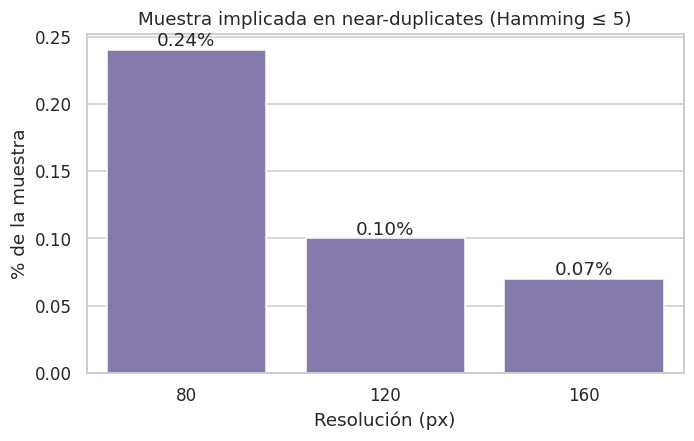

In [20]:

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=dup_df, x="resolution", y="%_muestra", ax=ax, color="#8172B3")
ax.set_title("Muestra implicada en near-duplicates (Hamming ≤ 5)")
ax.set_xlabel("Resolución (px)")
ax.set_ylabel("% de la muestra")
ax.bar_label(ax.containers[0], fmt="%.2f%%")
save_fig(fig, "05_duplicados.png")
plt.show()


## Análisis de posible filtración de información por WSI

Al tratar con imágenes que son realmente parches de una imágen más completa, **WSI*** (Whole Slide Image)
el principal riesgo que se nso presenta con respecto a ltratamiento de lso datos es la posibilidad de que diferentes parches de una misma imágen se encuentren dispersas entre los conjuntos de train, validación y test.
Si se da este caso el modelo puede memorizar textura/tinción local en lugar de aprender malignidad 
generalizable, inflando las métricas.

Para poder hacer un *split* que **no** mezcle WSIs entre particiones, necesitaríamos un
identificador por parche. Aquí examinamos los nombres de los archivos en
busca de ese identificador.

In [19]:
# Muestra de nombres de archivo por carpeta
for res in RESOLUTIONS:
    for cls in CLASSES:
        files  = list_images(res, cls)
        sample = random.Random(SEED).sample(files, min(6, len(files)))
        print(f"--- {res}px / {cls}  (n={len(files)}) ---")
        for f in sample:
            print("   ", f.name)


--- 80px / Normal  (n=87500) ---
    Normal-83811.png
    Normal-14593.png
    Normal-03279.png
    Normal-36049.png
    Normal-32099.png
    Normal-29257.png
--- 80px / Abnormal  (n=59151) ---
    Abnormal-41906.png
    Abnormal-07297.png
    Abnormal-01640.png
    Abnormal-48599.png
    Abnormal-18025.png
    Abnormal-16050.png
--- 120px / Normal  (n=40460) ---
    Normal-07297.png
    Normal-01640.png
    Normal-18025.png
    Normal-16050.png
    Normal-14629.png
    Normal-09145.png
--- 120px / Abnormal  (n=24801) ---
    Abnormal-20953.png
    Abnormal-03649.png
    Abnormal-00820.png
    Abnormal-24300.png
    Abnormal-09013.png
    Abnormal-08025.png
--- 160px / Normal  (n=20160) ---
    Normal-03649.png
    Normal-00820.png
    Normal-09013.png
    Normal-08025.png
    Normal-07315.png
    Normal-04573.png
--- 160px / Abnormal  (n=13124) ---
    Abnormal-10477.png
    Abnormal-01825.png
    Abnormal-00410.png
    Abnormal-12150.png
    Abnormal-04507.png
    Abnormal-04013.png


In [23]:
pattern = re.compile(r"^([A-Za-z]+)[-_]?(\d+)$") #expresión regular: nombre + guion o no guion + numeros


def parse_name(name):
    name_no_ext = Path(name).stem #stem para eliminar la extension

    m = pattern.match(name_no_ext)

    if m:
        prefix = m.group(1)
        numeric_index = int(m.group(2))

        return prefix, numeric_index

    else:
        return name_no_ext, None


struct_rows = []
for res in RESOLUTIONS:
    for cls in CLASSES:
        image_paths = list_images(res, cls)

        names = [f.name for f in image_paths]

        parsed_prefixes = {parse_name(n)[0] for n in names}
        prefixes = sorted(parsed_prefixes)


        token_counts = {len( re.split( r"[-_]", Path(n).stem ) ) for n in names}
        n_tokens = sorted(token_counts)

        resolution = int(res)

        example_name = names[0]

        struct_row = {"resolution": resolution,
                      "class": cls,
                      "prefijos_distintos": prefixes,
                      "n_tokens_por_nombre": n_tokens,
                      "ejemplo": example_name}
        
        struct_rows.append( struct_row)


    struct_df = pd.DataFrame(struct_rows)
        
struct_df


,resolution,class,prefijos_distintos,n_tokens_por_nombre,ejemplo
0,80,Normal,[Normal],[2],Normal-00001.png
1,80,Abnormal,[Abnormal],[2],Abnormal-00001.png
2,120,Normal,[Normal],[2],Normal-00001.png
3,120,Abnormal,[Abnormal],[2],Abnormal-00001.png
4,160,Normal,[Normal],[2],Normal-00001.png
5,160,Abnormal,[Abnormal],[2],Abnormal-00001.png


In [24]:
seq_rows = []

for res in RESOLUTIONS:
    for cls in CLASSES:
        image_paths = list_images(res, cls)

        parsed_indices = (parse_name(f.name)[1] for f in image_paths)

        idxs = sorted(parsed_indices)
        n_images = len(idxs)

        minimum_index = idxs[0]
        maximum_index = idxs[-1]

        expected_indices = list(range( 1, n_images + 1))
        is_contiguous = (idxs == expected_indices)

        resolution = int(res)

        seq_row = {
            "resolution": resolution,
            "class": cls,
            "n": n_images,
            "idx_min": minimum_index,
            "idx_max": maximum_index,
            "contigua_1..N": is_contiguous
        }

        seq_rows.append(seq_row)

seq_df = pd.DataFrame(seq_rows)

seq_df


,resolution,class,n,idx_min,idx_max,contigua_1..N
0,80,Normal,87500,1,87500,True
1,80,Abnormal,59151,1,59151,True
2,120,Normal,40460,1,40460,True
3,120,Abnormal,24801,1,24801,True
4,160,Normal,20160,1,20160,True
5,160,Abnormal,13124,1,13124,True


### Conclusión sobre el *leakage* por WSI

Podemos observar que los nombre de los archivos siguen un patrón, consta de la clase a la que pertenece y de un índice numérico (por ejemplo: `Abnormal-00001.png`). Sin embargo, el número no parece mantener relación ninguna con la WSI de orige ndel parche. 


Por lo tanto, no es posible reconstruir la agrupación por WSI a partir de los datos
disponibles. Encontramos aqui una limitación metodológica.

El README oficial de GasHisSDB describe un
*split* aleatorio de los conjuntos con uan distribución **40/40/20** (train/val/test). Con la información
disponible, ese es el protocolo reproducible para comparar co nel estado del arte, pero arrastra un
riesgo de fuga por WSI que no puede eliminarse.



## Consistencia entre resoluciones (80 / 120 / 160)

Comprobamos si las carpetas `80`, `120` y `160` son la misma fuente de tejido recortada
a distinta escala o conjuntos independientes, comparando las convenciones de nombres y la
proporción de clases.

In [22]:
conv_rows = []
for res in RESOLUTIONS:
    for cls in CLASSES:
        files = list_images(res, cls)
        conv_rows.append({"resolution": int(res), "class": cls, "n": len(files),
                          "primer_fichero": files[0].name, "ultimo_fichero": files[-1].name})
conv_df = pd.DataFrame(conv_rows)
conv_df


,resolution,class,n,primer_fichero,ultimo_fichero
0,80,Normal,87500,Normal-00001.png,Normal-87500.png
1,80,Abnormal,59151,Abnormal-00001.png,Abnormal-59151.png
2,120,Normal,40460,Normal-00001.png,Normal-40460.png
3,120,Abnormal,24801,Abnormal-00001.png,Abnormal-24801.png
4,160,Normal,20160,Normal-00001.png,Normal-20160.png
5,160,Abnormal,13124,Abnormal-00001.png,Abnormal-13124.png


[figura guardada] results/eda/07_proporcion_abnormal.png


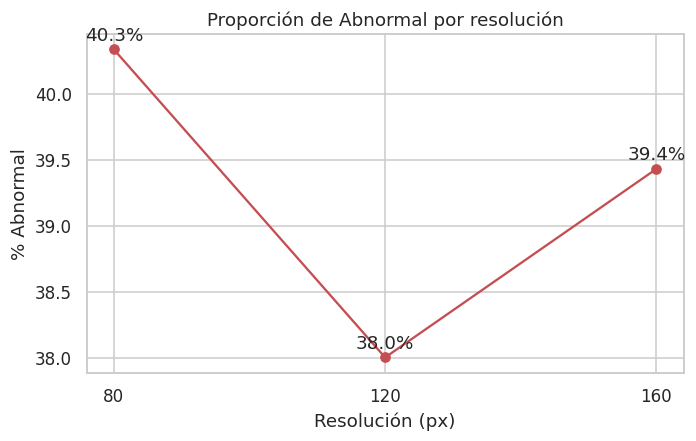

In [ ]:
# Proporción de Abnormal por resolución
frac    = inv.pivot(index="resolution", columns="class", values="n_images")
frac_ab = (frac["Abnormal"] / (frac["Abnormal"] + frac["Normal"]) * 100)

fig, ax = plt.subplots(figsize=(7, 4))
frac_ab.plot(marker="o", ax=ax, color="#C44E52")
ax.set_title("Proporción de Abnormal por resolución")
ax.set_xlabel("Resolución (px)")
ax.set_ylabel("% Abnormal")
ax.set_xticks(frac_ab.index)
for x, y in zip(frac_ab.index, frac_ab.values):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 6), ha="center")
save_fig(fig, "07_proporcion_abnormal.png")
plt.show()


**Lectura:** las tres resoluciones comparten la **misma convención de nombres**
(`<Clase>-<índice>`) y una **proporción de clases muy similar**, mientras que el número de
parches **decrece** al aumentar el tamaño (caben menos parches grandes por WSI). Todo ello
es consistente con que **80/120/160 son la misma fuente de WSIs recortada a tres escalas**,
no conjuntos independientes.

**Consecuencia metodológica:** las tres resoluciones **no deben combinarse como si fueran
datos independientes** (duplicaría información y agravaría el *leakage*). Cada resolución se
trata como un experimento separado; comparar entre resoluciones es un análisis de
*generalización cross-scale*, no una ampliación del tamaño muestral.

## Conclusiones del EDA


### Distribución de las clases

La distribución de las clases presenta un desbalance moderado y similar en las tres resoluciones analizadas. La clase `Normal` representa aproximadamente el 60 % de las imágenes, mientras que la clase `Abnormal` constituye alrededor del 38–40 %.

Aunque el desbalance no es especialmente elevado, la *accuracy* no debe utilizarse como única métrica de evaluación, ya que podría ocultar un rendimiento deficiente sobre la clase minoritaria. Por este motivo, será necesario incluir métricas como la sensibilidad o *recall* de la clase `Abnormal`, el F1-score, el área bajo la curva precisión-recall (AUC-PR) y la matriz de confusión.

Durante el entrenamiento, el desbalance podrá tratarse mediante pesos de clase en la función de pérdida y, si resulta necesario, mediante un aumento de datos específico para la clase minoritaria, que puede ser mejor idea que hacer un undersampling de la clase mayoritaria.

### Riesgo de fuga de información entre WSIs

Los nombres de los archivos siguen el formato `<Clase>-<índice>` y no contienen información sobre la WSI, el paciente o la muestra histológica de origen. Además, los índices corresponden únicamente a una secuencia numérica independiente para cada clase.

Por esta razón, no es posible reconstruir qué parches proceden de una misma WSI ni garantizar que los conjuntos de entrenamiento, validación y prueba sean independientes a nivel de lámina o paciente.

Para mantener la comparabilidad con los trabajos que utilizan GasHisSDB, la idea es seguir el reparto aleatorio 40/40/20 a nivel de parche indicado en el README oficial del dataset. Sin embargo, este procedimiento presenta un riesgo de fuga de información, ya que parches procedentes de una misma WSI podrían quedar distribuidos entre distintos conjuntos.

En consecuencia, los resultados deberán interpretarse como una estimación potencialmente optimista del rendimiento de generalización. 


### Imágenes duplicadas o muy similares

El análisis mediante hashing se realizó sobre una muestra de 10 000 imágenes por resolución, considerando como imágenes cercanas aquellas cuya distancia de Hamming fuera menor o igual que 5. Los resultados concretos se muestran en la tabla de la sección 5.

La presencia de imágenes visualmente similares puede ser esperable en un dataset histopatológico, ya que distintos parches pueden proceder de regiones cercanas de un mismo tejido. Por tanto, la existencia de imágenes parecidas no constituye necesariamente un problema por sí misma.

El principal riesgo aparece cuando imágenes duplicadas o muy similares quedan distribuidas entre los conjuntos de entrenamiento y prueba. En ese caso, el modelo podría obtener mejores resultados por haber observado durante el entrenamiento imágenes casi equivalentes a las utilizadas en la evaluación.

Este riesgo está directamente relacionado con la imposibilidad de realizar una separación por WSI descrita en el apartado anterior.

### Diferencias de color y tinción entre clases

Se calcularon las intensidades medias de los canales rojo, verde y azul para las clases `Normal` y `Abnormal`. Para determinar si el color permite distinguir fácilmente ambas clases, las diferencias entre sus valores medios deben analizarse junto con la variabilidad existente dentro de cada clase.

Si la diferencia media entre `Normal` y `Abnormal` es pequeña en comparación con la dispersión interna de las clases, puede considerarse que el color global no permite separar trivialmente ambas categorías. Esto reduciría, aunque no eliminaría, el riesgo de que el modelo aprendiera un atajo basado únicamente en diferencias generales de tinción.



